In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
L = tf.keras.layers

In [3]:
tr = pd.read_csv("mnist_train.csv")
te = pd.read_csv("mnist_test.csv")
Xtr,ytr = tr.drop(columns="label").values.reshape(-1,28,28,1) / 255, tr.label.values
Xte,yte = te.drop(columns="label").values.reshape(-1,28,28,1) / 255, te.label.values

In [4]:
model = tf.keras.Sequential([L.Flatten(), L.Dense(256, activation="relu"), L.Dense(128, activation="relu"), L.Dense(10, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=11, batch_size=128, validation_data=(Xte, yte))

Epoch 1/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5391 - loss: 1.6852 - val_accuracy: 0.8688 - val_loss: 0.5559
Epoch 2/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8713 - loss: 0.5127 - val_accuracy: 0.8957 - val_loss: 0.3843
Epoch 3/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8955 - loss: 0.3855 - val_accuracy: 0.9100 - val_loss: 0.3296
Epoch 4/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9049 - loss: 0.3418 - val_accuracy: 0.9149 - val_loss: 0.3009
Epoch 5/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9109 - loss: 0.3099 - val_accuracy: 0.9209 - val_loss: 0.2773
Epoch 6/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9208 - loss: 0.2830 - val_accuracy: 0.9240 - val_loss: 0.2628
Epoch 7/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9248 - loss: 0.2667 - val_accuracy: 0.9298 - val_loss: 0.2470
Epoch 8/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9285 - loss: 0.2571 - val_accuracy: 0.

In [6]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9306 - loss: 0.2439
[0.20960073173046112, 0.9394999742507935]
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       980
           1       0.97      0.98      0.98      1135
           2       0.95      0.92      0.94      1032
           3       0.93      0.93      0.93      1010
           4       0.93      0.95      0.94       982
           5       0.93      0.92      0.92       892
           6       0.94      0.95      0.94       958
           7       0.95      0.93      0.94      1028
           8       0.92      0.91      0.91       974
           9       0.92      0.92      0.92      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



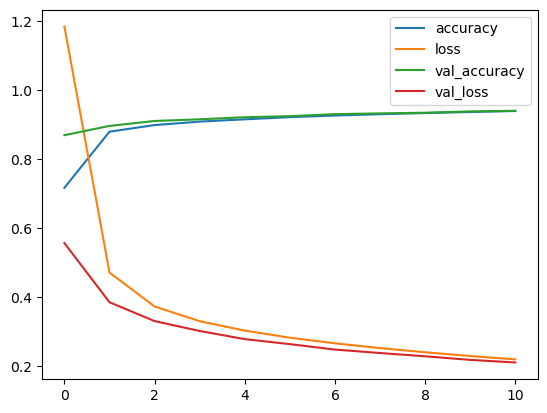

In [7]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


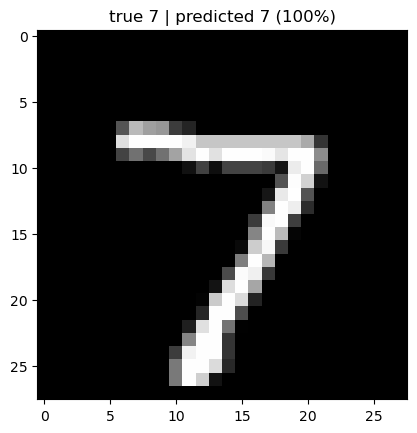

In [8]:
#one example
names = [str(k) for k in range(10)]
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()